# 06 — The decoder decides the answer, not only the error rate

Decoding with the paper's phenomenological graph (the natural choice when
only p_data and p_read are known) against decoding with the circuit's full detector error model,
on the same detection events.

**Source:** `python -m qec_timing.studies.decoders` → `results/decoders/decoders.json`. The
premise study's native-gate runs (linear idle γ = 0.3 p2), each decoded twice: PyMatching on the
circuit's exact DEM, and PyMatching on the paper's model with the same circuit's measured
p_data(Δt) and p_read.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
dec = json.loads((R / "decoders" / "decoders.json").read_text())
for r in dec["rows"]:
    ratio = np.array([p["pL_paper"] / p["pL_full"] for p in r["points"]])
    print(f"d={r['d']} {r['idle']}: p_L ratio (paper graph / full DEM) {ratio.min():.2f}-{ratio.max():.2f};  "
          f"dt* full {r['optimum_full']['dt_star']:.2f}, with the paper graph {r['optimum_paper']['dt_star']:.2f}")

d=3 lin 0.3: p_L ratio (paper graph / full DEM) 1.01-1.65;  dt* full 9.73, with the paper graph 23.65
d=5 lin 0.3: p_L ratio (paper graph / full DEM) 1.04-2.11;  dt* full 5.15, with the paper graph 15.88
d=7 lin 0.3: p_L ratio (paper graph / full DEM) 1.19-3.09;  dt* full 3.39, with the paper graph 9.91


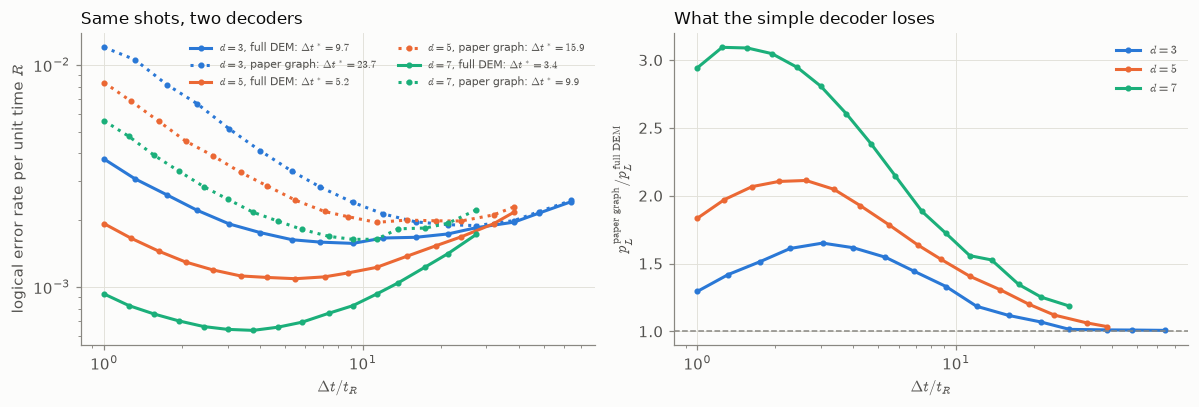

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for r in dec["rows"]:
    c = P.D_COLOR[r["d"]]; pts = r["points"]
    dt = [p["dt"] for p in pts]
    axes[0].plot(dt, [p["r_full"] for p in pts], "-o", color=c, ms=3,
                 label=rf"$d = {r['d']}$, full DEM: $\Delta t^* = {r['optimum_full']['dt_star']:.1f}$")
    axes[0].plot(dt, [p["r_paper"] for p in pts], ":", marker="o", ms=3, color=c,
                 label=rf"$d = {r['d']}$, paper graph: $\Delta t^* = {r['optimum_paper']['dt_star']:.1f}$")
    axes[1].plot(dt, [p["pL_paper"] / p["pL_full"] for p in pts], "o-", color=c, ms=3, label=P.dl(r["d"]))
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].legend(fontsize=7, ncol=2)
axes[0].set_xlabel(P.DT_TR); axes[0].set_ylabel(P.RATE)
axes[0].set_title("Same shots, two decoders", loc="left")
axes[1].axhline(1, color=P.MUTED, lw=1, ls="--"); axes[1].set_xscale("log"); axes[1].legend(fontsize=8)
axes[1].set_xlabel(P.DT_TR); axes[1].set_ylabel(r"$p_L^{\rm paper\ graph} / p_L^{\rm full\ DEM}$")
axes[1].set_title("What the simple decoder loses", loc="left")
fig.tight_layout()
P.save(fig, "06_decoder_matters_1")

**Reading.**
- *Measured:* the phenomenological graph loses most at short intervals, where mid-round and
  hook faults (which it cannot represent) are a larger share of all faults, and the loss grows
  with distance.
- *Measured, the important part:* because the loss depends on Δt, the simple decoder also moves
  the optimum, here to a much longer interval. A study that used it would recommend the wrong
  interval. Every circuit-level result in this repo decodes with the full DEM.